In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

In [2]:
# Sử dụng hàm convolve2d của Gấm
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

## Tấn Lên – Demo 3b: Phát hiện biên Sobel và Làm sắc nét ảnh

**Mục tiêu:**
- Áp dụng các kernel Sobel X và Sobel Y để tính toán gradient của ảnh.
- Tính toán độ lớn và hướng của gradient.
- Áp dụng toán tử Laplacian để làm sắc nét ảnh.
- Trực quan hóa và phân tích kết quả xử lý.

Các thí nghiệm sử dụng hàm `convolve2d` của nhóm để thực hiện phép chập với các kernel khác nhau.

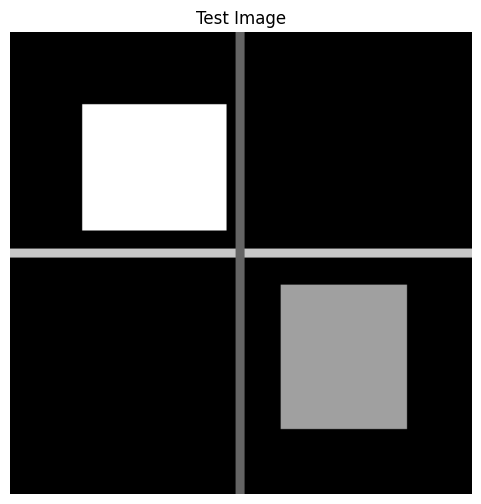

In [3]:
#  Tạo ảnh thử nghiệm 
height, width = 256, 256
img_demo = np.zeros((height, width), dtype=np.uint8)

# Add bright and gray rectangles
img_demo[40:110, 40:120] = 255
img_demo[140:220, 150:220] = 160

# Add horizontal and vertical structures
img_demo[120:125, :] = 200
img_demo[:, 125:130] = 100

# Display the test image
plt.figure(figsize=(6, 6))
plt.imshow(img_demo, cmap="gray", vmin=0, vmax=255)
plt.title("Test Image")
plt.axis("off")
plt.show()

In [4]:
 
# Sobel edge detection

img_float = img_demo.astype(np.float64)

sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# convolve2d thực hiện tích chập thật nên cần lật kernel
sobel_x_conv = np.flip(sobel_x, axis=(0, 1))
sobel_y_conv = np.flip(sobel_y, axis=(0, 1))

gx = convolve2d(
    img_float, sobel_x_conv, padding="reflect"
)

gy = convolve2d(
    img_float, sobel_y_conv, padding="reflect"
)

edge_magnitude = np.sqrt(gx**2 + gy**2)

edge_direction = np.degrees(
    np.arctan2(gy, gx)
)

print("Sobel completed!")
print("gx:", gx.shape)
print("gy:", gy.shape)
 

Sobel completed!
gx: (256, 256)
gy: (256, 256)


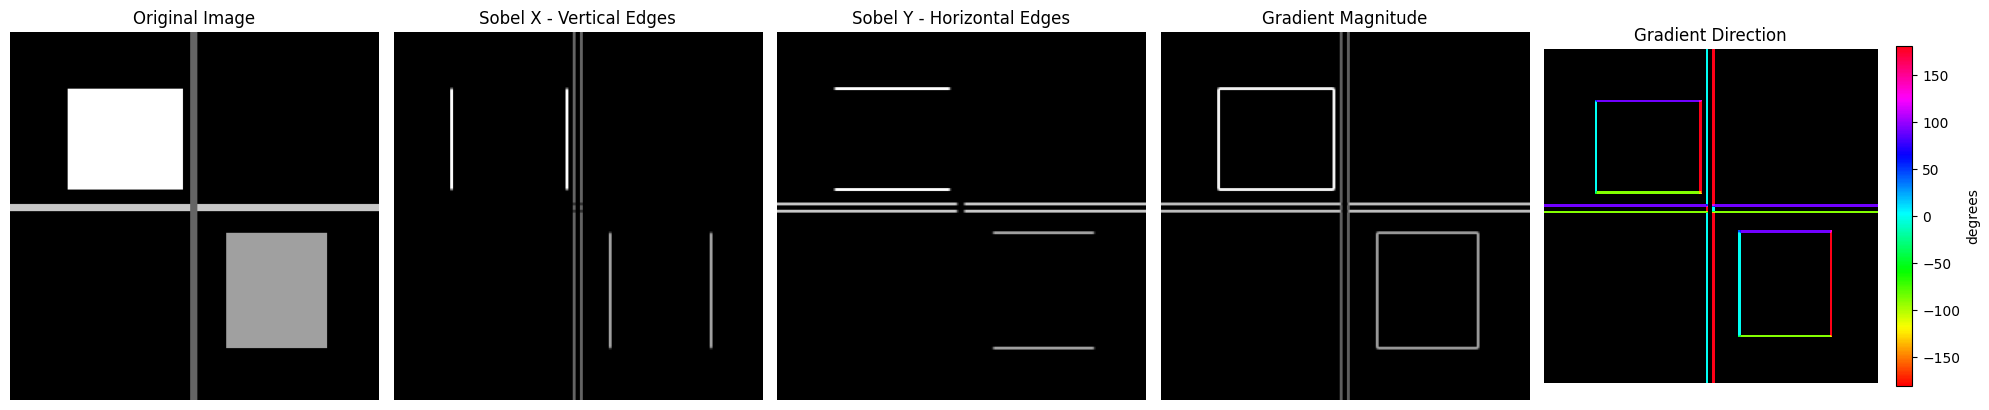

In [5]:
 
# Visualize Sobel edge detection

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img_demo, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(np.abs(gx), cmap="gray")
axes[1].set_title("Sobel X - Vertical Edges")

axes[2].imshow(np.abs(gy), cmap="gray")
axes[2].set_title("Sobel Y - Horizontal Edges")

axes[3].imshow(edge_magnitude, cmap="gray")
axes[3].set_title("Gradient Magnitude")

# Chỉ tô màu hướng ở pixel có cạnh; vùng phẳng (gx = gy = 0) để đen
direction_display = np.where(edge_magnitude > 0, edge_direction, np.nan)
direction_cmap = plt.get_cmap("hsv").copy()
direction_cmap.set_bad("black")
im = axes[4].imshow(direction_display, cmap=direction_cmap, vmin=-180, vmax=180,
                    interpolation="nearest")
axes[4].set_title("Gradient Direction")
fig.colorbar(im, ax=axes[4], fraction=0.046, label="degrees")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

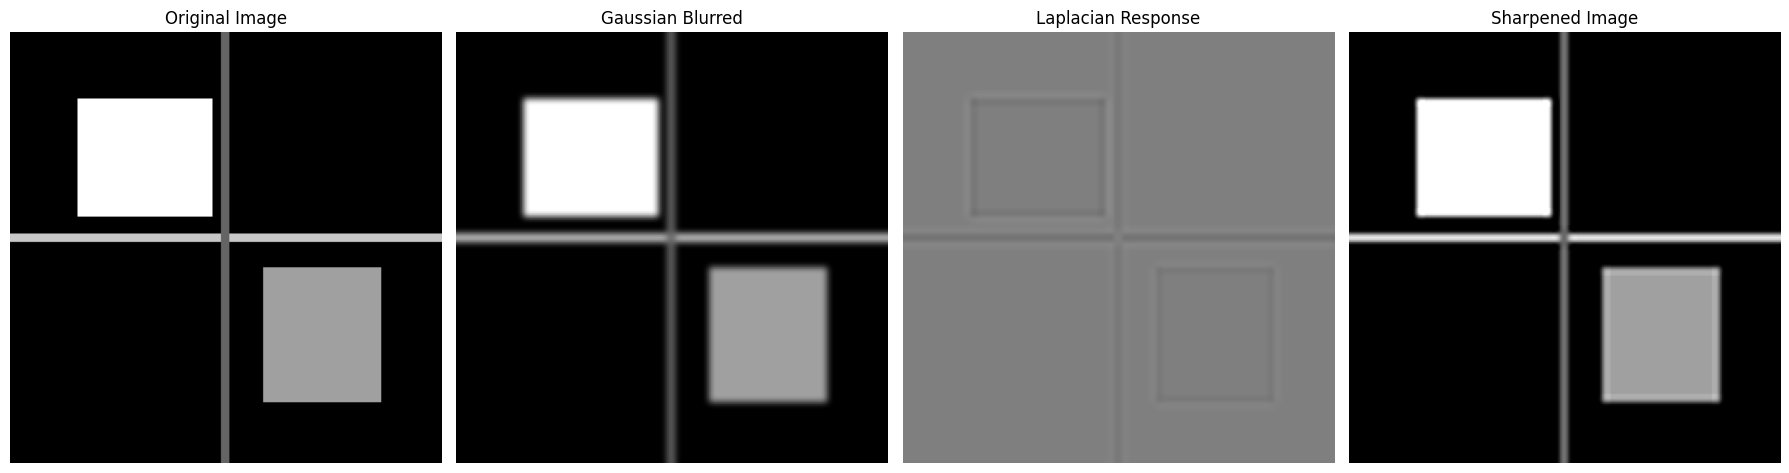

In [6]:
# Convert original image to float64
img_float = img_demo.astype(np.float64)

# Kernel Gauss tự viết, làm mờ bằng convolve2d của nhóm
def gaussian_kernel(size, sigma):
    r = size // 2
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return kernel / kernel.sum()

# Blur the image first to make the sharpening effect more visible
img_blurred = convolve2d(
    img_float,
    gaussian_kernel(9, 2.0),
    padding="reflect"
)

# 4-neighbor Laplacian kernel
laplacian_kernel = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=np.float64)

# Apply Laplacian to the blurred image
laplacian = convolve2d(
    img_blurred,
    laplacian_kernel,
    padding="reflect"
)

# Sharpen the blurred image
alpha = 3.0
sharpened_float = img_blurred - alpha * laplacian

# Clip to valid image range
sharpened = np.clip(
    np.round(sharpened_float), 0, 255
).astype(np.uint8)

# Convert for display
img_blurred_display = np.clip(
    np.round(img_blurred), 0, 255
).astype(np.uint8)

laplacian_display = np.clip(
    127.5 + laplacian / 2, 0, 255
).astype(np.uint8)

# Compare original, blurred, Laplacian and sharpened images
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(
    img_blurred_display, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("Gaussian Blurred")

axes[2].imshow(
    laplacian_display, cmap="gray", vmin=0, vmax=255
)
axes[2].set_title("Laplacian Response")

axes[3].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

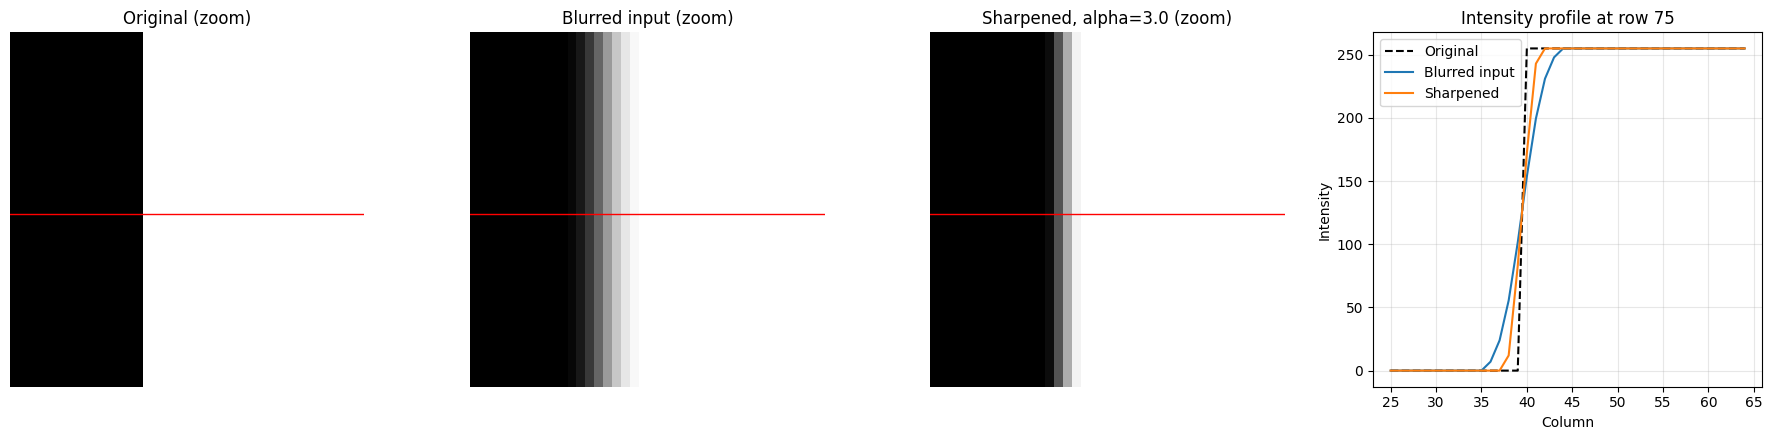

Edge width - blurred:   4 px
Edge width - sharpened: 2 px


In [7]:
# Phóng to vùng cạnh để so sánh gốc / mờ / sắc nét
r0, r1, c0, c1 = 55, 95, 25, 65   # vùng quanh cạnh trái của hình chữ nhật sáng
row = 75                          # hàng dùng để vẽ mặt cắt cường độ

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, im, title in zip(
    axes[:3],
    [img_demo, img_blurred_display, sharpened],
    ["Original (zoom)", "Blurred input (zoom)", f"Sharpened, alpha={alpha} (zoom)"]
):
    ax.imshow(im[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=255,
              interpolation="nearest")
    ax.axhline(row - r0, color="red", linewidth=1)
    ax.set_title(title)
    ax.axis("off")

cols = np.arange(c0, c1)
axes[3].plot(cols, img_demo[row, c0:c1], "k--", label="Original")
axes[3].plot(cols, img_blurred[row, c0:c1], label="Blurred input")
axes[3].plot(cols, sharpened[row, c0:c1], label="Sharpened")
axes[3].set_xlabel("Column")
axes[3].set_ylabel("Intensity")
axes[3].set_title(f"Intensity profile at row {row}")
axes[3].legend()
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Độ rộng vùng chuyển (pixel có cường độ 10%–90%) càng nhỏ thì cạnh càng sắc
def edge_width(profile):
    return int(np.sum((profile > 25.5) & (profile < 229.5)))

print("Edge width - blurred:  ", edge_width(img_blurred[row, c0:c1]), "px")
print("Edge width - sharpened:", edge_width(sharpened[row, c0:c1]), "px")

In [8]:
# Kiểm tra kích thước, kiểu dữ liệu và kết quả

# 1. Kiểm tra các biến đầu vào đã tồn tại chưa
required_vars = [
    "img_demo",
    "gx",
    "gy",
    "edge_magnitude",
    "edge_direction",
    "laplacian",
    "sharpened"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    print("ERROR: Các biến chưa được tạo:", missing_vars)
    print("Hãy chạy lại các cell tạo ảnh, Sobel và Laplacian ở phía trên.")
else:
    # 2. In kích thước và kiểu dữ liệu
    print("Original image:", img_demo.shape, img_demo.dtype)
    print("Sobel X:", gx.shape, gx.dtype)
    print("Sobel Y:", gy.shape, gy.dtype)
    print("Gradient magnitude:", edge_magnitude.shape,
          edge_magnitude.dtype)
    print("Gradient direction:", edge_direction.shape,
          edge_direction.dtype)
    print("Laplacian:", laplacian.shape, laplacian.dtype)
    print("Sharpened image:", sharpened.shape, sharpened.dtype)

    # 3. Thống kê gradient
    print("\nMaximum gradient magnitude:",
          float(np.max(edge_magnitude)))

    print("Number of pixels with nonzero gradient:",
          int(np.count_nonzero(edge_magnitude)))

    # 4. Kiểm tra các đầu ra có cùng kích thước không
    all_shapes_match = (
        img_demo.shape == gx.shape
        == gy.shape
        == edge_magnitude.shape
        == edge_direction.shape
        == laplacian.shape
        == sharpened.shape
    )

    print("All output shapes match:", all_shapes_match)

    # 5. Kiểm tra giá trị không hợp lệ
    arrays_to_check = {
        "gx": gx,
        "gy": gy,
        "edge_magnitude": edge_magnitude,
        "edge_direction": edge_direction,
        "laplacian": laplacian,
        "sharpened": sharpened
    }

    for name, array in arrays_to_check.items():
        print(
            f"{name} contains NaN/Inf:",
            bool(np.any(~np.isfinite(array)))
        )


Original image: (256, 256) uint8
Sobel X: (256, 256) float64
Sobel Y: (256, 256) float64
Gradient magnitude: (256, 256) float64
Gradient direction: (256, 256) float64
Laplacian: (256, 256) float64
Sharpened image: (256, 256) uint8

Maximum gradient magnitude: 1081.8733752154178
Number of pixels with nonzero gradient: 3220
All output shapes match: True
gx contains NaN/Inf: False
gy contains NaN/Inf: False
edge_magnitude contains NaN/Inf: False
edge_direction contains NaN/Inf: False
laplacian contains NaN/Inf: False
sharpened contains NaN/Inf: False


## KT3 – Ảnh thử

## KT3 – hough_accumulate, find_peaks